# Chemical kinetics: rate laws, Arrhenius analysis and reaction networks

Worked examples with `kinetix`:

1. telling reaction orders apart from concentration-time data,
2. extracting an activation energy from rate constants measured at several temperatures,
3. the consecutive reaction A → B → C and its intermediate maximum,
4. a reversible association reaching equilibrium,
5. the Lotka–Volterra autocatalytic oscillator written as a mass-action network.

The data in sections 1 and 2 are **synthetic**. They're generated from known parameters plus noise to show the fitting procedure.

In [1]:
import sys, math
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import kinetix as kx

rng = np.random.default_rng(7)

## 1. Which order fits?

R^2 of linearised fits: {0: 0.82406, 1: 0.95548, 2: 0.99975}
best order = 2, k = 0.1201  (true: 2, 0.12)


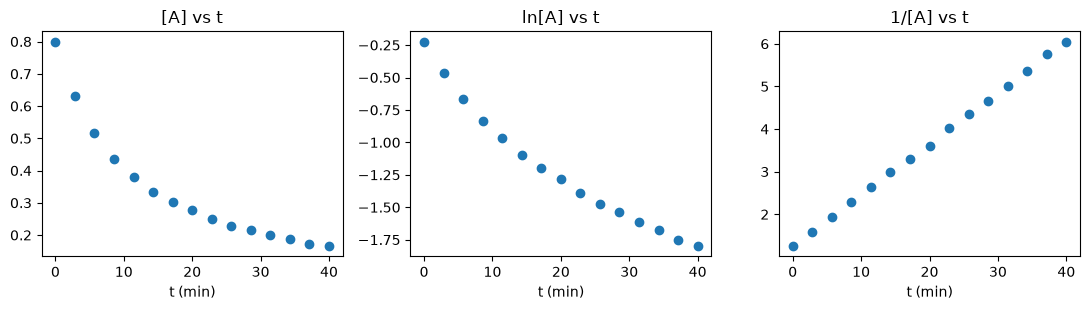

In [2]:
t = np.linspace(0, 40, 15)
c_true = kx.integrated(2, 0.8, 0.12, t)
c_obs = c_true * (1 + 0.01 * rng.standard_normal(t.size))
res = kx.fit_order(t, c_obs)
print("R^2 of linearised fits:", {n: round(r, 5) for n, r in res["r2"].items()})
print(f"best order = {res['order']}, k = {res['k']:.4f}  (true: 2, 0.12)")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (lab, y) in zip(axes, [("[A]", c_obs), ("ln[A]", np.log(c_obs)), ("1/[A]", 1 / c_obs)]):
    ax.plot(t, y, "o"); ax.set_title(lab + " vs t"); ax.set_xlabel("t (min)")
plt.tight_layout(); plt.show()

## 2. Arrhenius plot

Ea = 67.0 kJ/mol, A = 2.65e+10 s^-1, R^2 = 0.9998  (true: 68.0 kJ/mol, 4.0e10)


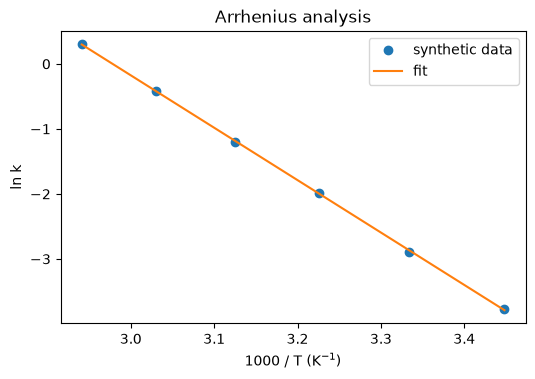

In [3]:
T = np.array([290, 300, 310, 320, 330, 340.0])
k_obs = kx.arrhenius(4.0e10, 68_000, T) * np.exp(0.03 * rng.standard_normal(T.size))
fit = kx.fit_arrhenius(T, k_obs)
print(f"Ea = {fit['Ea']/1000:.1f} kJ/mol, A = {fit['A']:.2e} s^-1, R^2 = {fit['r2']:.4f}  (true: 68.0 kJ/mol, 4.0e10)")

x = 1000 / T
plt.figure(figsize=(6, 3.8))
plt.plot(x, np.log(k_obs), "o", label="synthetic data")
xx = np.linspace(x.min(), x.max(), 50)
plt.plot(xx, np.log(fit["A"]) - fit["Ea"] / kx.R_GAS * xx / 1000, label="fit")
plt.xlabel("1000 / T (K$^{-1}$)"); plt.ylabel("ln k"); plt.legend(); plt.title("Arrhenius analysis")
plt.show()

## 3. Consecutive first-order reactions

The intermediate B peaks at $t_{max} = \ln(k_1/k_2)/(k_1-k_2)$.

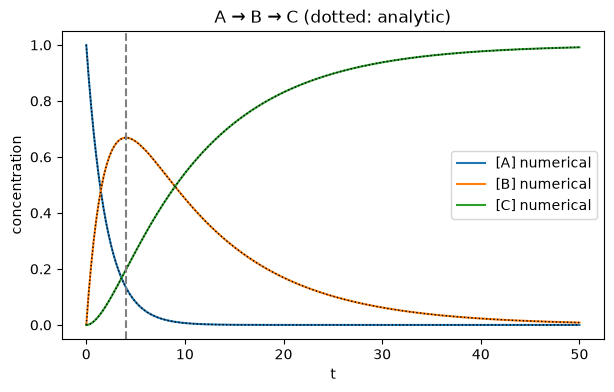

t_max = 4.024, max deviation numerical vs analytic = 9.28e-11


In [4]:
k1, k2 = 0.5, 0.1
net = kx.ReactionNetwork.from_text(f"""
A -> B ; k = {k1}
B -> C ; k = {k2}
""")
sim = net.simulate({"A": 1.0}, t_end=50)
A_an, B_an, C_an = kx.consecutive_first_order(1.0, k1, k2, sim.t)
t_max = math.log(k1 / k2) / (k1 - k2)

plt.figure(figsize=(7, 4))
for s, an in zip("ABC", (A_an, B_an, C_an)):
    plt.plot(sim.t, sim[s], label=f"[{s}] numerical")
    plt.plot(sim.t, an, "k:", lw=1)
plt.axvline(t_max, ls="--", c="gray")
plt.xlabel("t"); plt.ylabel("concentration"); plt.legend(); plt.title("A → B → C (dotted: analytic)")
plt.show()
print(f"t_max = {t_max:.3f}, max deviation numerical vs analytic = {np.max(abs(sim['B'] - B_an)):.2e}")

## 4. Reversible association A + B ⇌ C

[C]/([A][B]) at the end = 4.0000  (K = kf/kb = 4.0)


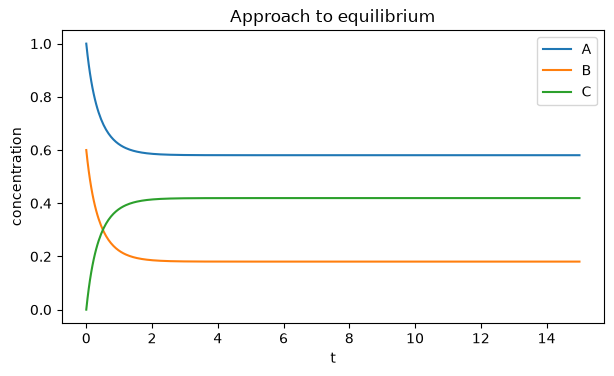

In [5]:
kf, kb = 2.0, 0.5
eq = kx.ReactionNetwork.from_text(f"A + B <-> C ; kf = {kf}, kb = {kb}")
sim = eq.simulate({"A": 1.0, "B": 0.6}, t_end=15)
fin = sim.final()
print(f"[C]/([A][B]) at the end = {fin['C']/(fin['A']*fin['B']):.4f}  (K = kf/kb = {kf/kb})")
plt.figure(figsize=(7, 3.8))
for s in eq.species:
    plt.plot(sim.t, sim[s], label=s)
plt.xlabel("t"); plt.ylabel("concentration"); plt.legend(); plt.title("Approach to equilibrium")
plt.show()

## 5. Lotka–Volterra autocatalysis

A precursor reservoir X, held constant, feeds the autocatalytic steps
X + Y → 2Y, Y + Z → 2Z and Z → P. This produces sustained oscillations.

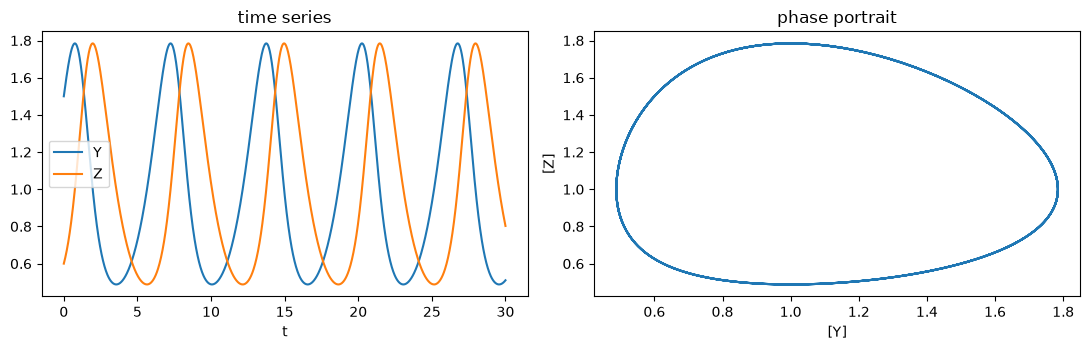

In [6]:
lv = kx.ReactionNetwork.from_text("""
X + Y -> X + 2Y ; k = 1.0
Y + Z -> 2Z     ; k = 1.0
Z -> P          ; k = 1.0
""")
sim = lv.simulate({"X": 1.0, "Y": 1.5, "Z": 0.6}, t_end=30, n_points=1500)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(sim.t, sim["Y"], label="Y"); axes[0].plot(sim.t, sim["Z"], label="Z")
axes[0].set_xlabel("t"); axes[0].legend(); axes[0].set_title("time series")
axes[1].plot(sim["Y"], sim["Z"]); axes[1].set_xlabel("[Y]"); axes[1].set_ylabel("[Z]"); axes[1].set_title("phase portrait")
plt.tight_layout(); plt.show()